# Modelling: does model complexity improve out-of-sample forecasting?

Do Ridge, Elastic Net and LightGBM forecast cross-sectional returns better out of sample than three simple
baselines: B0 (short-term reversal, `-z_ret_5d`), B1 (an equal-weight composite of four family representatives with the
pre-registered signs) and B2 (an expanding-window Fama-MacBeth forecast)? The design is fixed in
[`configs/models.yaml`](../configs/models.yaml) and was committed before any model was fitted. Every number here
comes from `python -m src.run_models`; this notebook only loads its outputs and holds the interpretation. Gross
statistics only: no portfolios, optimiser or costs.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

sys.path.insert(0, "..")

from src import model_plots as plots
from src.model_report import ablation_table, comparison_table, headline_table, period_table, sign_table

OUT = Path("../reports/models")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)
read = lambda name: pd.read_csv(OUT / f"{name}.csv")

meta = json.loads((OUT / "run_metadata.json").read_text())
headline = headline_table(OUT)
daily_ic = pd.read_parquet(OUT / "cache" / "daily_ic.parquet")
{k: meta[k] for k in ["config_commit", "config_dirty", "first_oos_date", "last_oos_date", "n_oos_rows",
                      "models_run", "primary_variant", "seed", "runtime_seconds"]}

{'config_commit': 'ebb38e585ce55216196d38f74bc210818dd81580',
 'config_dirty': False,
 'first_oos_date': '2007-01-03',
 'last_oos_date': '2021-11-30',
 'n_oos_rows': 1885735,
 'models_run': ['ridge', 'elastic_net', 'lightgbm'],
 'primary_variant': 'rank',
 'seed': 42,
 'runtime_seconds': 2352.4}

**Setup.** Expanding window, refit every January; the first test year is 2007, so the dot-com years, when the
signals were strongest, are training data only. Training rows whose label window reaches the first test date are
purged. Hyperparameters are chosen on the last two years of each training window, purged the same way, by mean daily
Spearman IC. Targets are `fwd_ret_5d_xs` and `fwd_ret_21d_xs`, either as within-date ranks (the primary variant, chosen
because of the pre-model diagnostics) or raw. Evaluation always uses the raw label `fwd_ret_{h}d`. The OOS window is
2007-01-03 to 2021-11-30 (1.89m stock-days); the holdout from 2022 is never read.

## 1. Out-of-sample IC

In [2]:
display(headline[["column", "ic_mean", "ic_ir", "hit_rate", "nw_t", "p_value_holm", "reject_holm",
                  "ic_mean_dispersion_weighted", "oos_r2_vs_zero"]].round(4))

,column,ic_mean,ic_ir,hit_rate,nw_t,p_value_holm,reject_holm,ic_mean_dispersion_weighted,oos_r2_vs_zero
0,B0_reversal_h5,0.0123,0.0717,0.5156,2.5382,0.2005,False,0.0167,NaN
1,B1_composite_h5,0.0161,0.0679,0.5372,2.0756,0.6448,False,0.0019,NaN
2,B2_fama_macbeth_h5_rank,0.0109,0.0548,0.5166,1.7492,1.0000,False,-0.0008,-0.0002
3,ridge_h5_rank,0.0120,0.0553,0.5361,1.7309,1.0000,False,-0.0008,0.0002
4,elastic_net_h5_rank,0.0129,0.0630,0.5345,1.9997,0.7284,False,0.0020,-0.0000
5,lightgbm_h5_rank,0.0174,0.1048,0.5491,3.4956,0.0095,True,0.0114,0.0001
6,B2_fama_macbeth_h5_raw,0.0079,0.0499,0.5204,1.7464,1.0000,False,0.0052,-0.0006
7,ridge_h5_raw,0.0059,0.0352,0.4999,1.2984,1.0000,False,0.0079,-0.0004
8,elastic_net_h5_raw,0.0090,0.0551,0.5009,1.9935,0.7284,False,0.0111,-0.0001
9,lightgbm_h5_raw,0.0101,0.0681,0.5185,2.6056,0.1743,False,0.0144,-0.0001


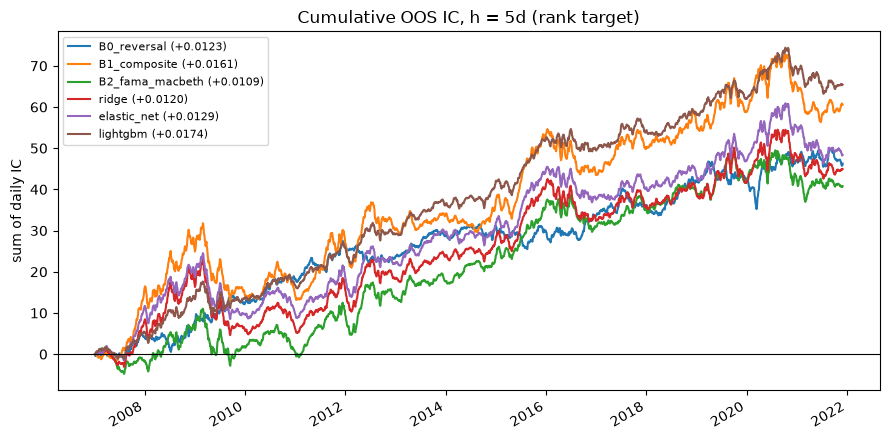

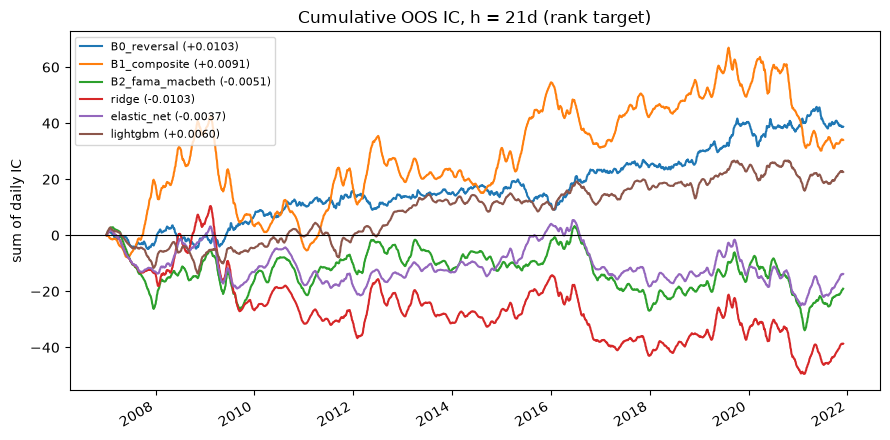

In [3]:
for h in (5, 21):
    plots.plot_cumulative_ic(daily_ic, read("ic_summary"), h, "rank");

**One predictor survives Holm.** Of the 20 IC tests, only LightGBM on the 5-day rank target is significant after
Holm adjustment: mean daily IC 0.0174, NW t 3.50, Holm p 0.010. The reversal baseline B0 has an IC of 0.0123 (t 2.54,
Holm p 0.20). At 21 days nothing is significant, and the three linear forecasts (B2, Ridge, Elastic Net) have
negative mean ICs.

- **The rank target is better than the raw one for every model at h = 5** (Ridge 0.0120 vs 0.0059, Elastic Net
  0.0129 vs 0.0090, LightGBM 0.0174 vs 0.0101). This matches the diagnostics: raw-return losses are dominated by
  high-dispersion days and right tails.
- **OOS R² against a zero forecast is about zero** (between -0.003 and +0.0002), as expected for cross-sectional
  return forecasts. It says nothing about ranking skill.
- **The rank-target linear models earn their IC on quiet days.** Weighted by daily dispersion, Ridge, Elastic Net
  and B2 on the 5-day rank target fall to about zero (-0.001 to +0.002). B0 and LightGBM keep their IC on dispersed
  days (B0: 0.0167, LightGBM 5d rank: 0.0114).

## 2. Does each step in complexity help?

Paired tests on the daily IC difference (model minus baseline), NW t with `max(h, plug-in)` lags, Holm over all
36 comparisons.

In [4]:
display(comparison_table(OUT).round(4))

,model,baseline,horizon,variant,ic_diff_mean,nw_t,p_value,p_value_holm,reject_holm
0,ridge,B2_fama_macbeth,5,rank,0.0011,0.3579,0.7204,1.0000,False
1,elastic_net,ridge,5,rank,0.0009,0.4748,0.6349,1.0000,False
2,lightgbm,ridge,5,rank,0.0055,1.4824,0.1382,1.0000,False
3,ridge,B0_reversal,5,rank,-0.0004,-0.0462,0.9631,1.0000,False
4,elastic_net,B0_reversal,5,rank,0.0006,0.0791,0.9369,1.0000,False
5,lightgbm,B0_reversal,5,rank,0.0051,1.0178,0.3088,1.0000,False
6,ridge,B1_composite,5,rank,-0.0042,-1.4068,0.1595,1.0000,False
7,elastic_net,B1_composite,5,rank,-0.0032,-0.8574,0.3912,1.0000,False
8,lightgbm,B1_composite,5,rank,0.0013,0.2408,0.8097,1.0000,False
9,ridge,B2_fama_macbeth,5,raw,-0.0020,-0.5402,0.5891,1.0000,False


**No complexity step helps significantly. This is a null result.** None of the 36 comparisons is rejected by
Holm. Every unadjusted |t| is at most 2.4, and that largest one is Ridge losing to B1 at 21 days.

- **Shrinkage (Ridge vs B2):** +0.0011 at 5 days on the rank target (t 0.36), and negative in the other three cases.
- **Sparsity (Elastic Net vs Ridge):** small positive differences, t between 0.1 and 1.3.
- **Non-linearity (LightGBM vs Ridge):** positive in all four horizon x target cases, +0.004 to +0.016, but t only
  1.2 to 1.6.
- **Against the simple baselines:** the most complex model, LightGBM, beats B0 by +0.005 IC at 5 days (t 1.02) and B1 by
  +0.001 (t 0.24). Ridge and Elastic Net differ from B0 and B1 by -0.021 to +0.001, never significantly.

The only predictor with a significant OOS IC is LightGBM, but its edge over a one-feature reversal score cannot be told
apart from noise over 15 years of OOS data.

## 3. Decile portfolios and turnover (gross)

D10 - D1 on non-overlapping rebalance dates. `beta_hedged` hedges each leg with its mean `beta_252d` against the
equal-weighted market (the primary spread, from the diagnostics); `rank` is the mean within-date return rank in
[-0.5, 0.5]. Turnover is one-way per leg per rebalance.

In [5]:
display(headline[["column", "beta_hedged_mean", "beta_hedged_nw_t", "rank_mean", "rank_nw_t",
                  "rank_autocorrelation", "turnover_D1", "turnover_D10"]].round(4))

,column,beta_hedged_mean,beta_hedged_nw_t,rank_mean,rank_nw_t,rank_autocorrelation,turnover_D1,turnover_D10
0,B0_reversal_h5,0.0022,1.9204,0.0097,1.5142,-0.0143,0.8758,0.8568
1,B1_composite_h5,0.0007,0.6423,0.0157,1.8323,0.8105,0.2887,0.5147
2,B2_fama_macbeth_h5_rank,0.0001,0.1458,0.0069,1.0481,0.7261,0.4466,0.4730
3,ridge_h5_rank,0.0001,0.0486,0.0097,1.2988,0.6393,0.5092,0.5621
4,elastic_net_h5_rank,0.0005,0.4877,0.0098,1.3756,0.5948,0.5879,0.5496
5,lightgbm_h5_rank,0.0013,1.4164,0.0201,3.1492,0.4092,0.5444,0.7480
6,B2_fama_macbeth_h5_raw,0.0008,0.9394,0.0029,0.5079,0.4995,0.6439,0.6325
7,ridge_h5_raw,0.0003,0.4325,0.0025,0.4278,0.2859,0.7741,0.7749
8,elastic_net_h5_raw,0.0010,1.1340,0.0051,0.8474,0.1644,0.8154,0.8125
9,lightgbm_h5_raw,0.0020,2.3251,0.0102,1.9115,0.1385,0.6861,0.7637


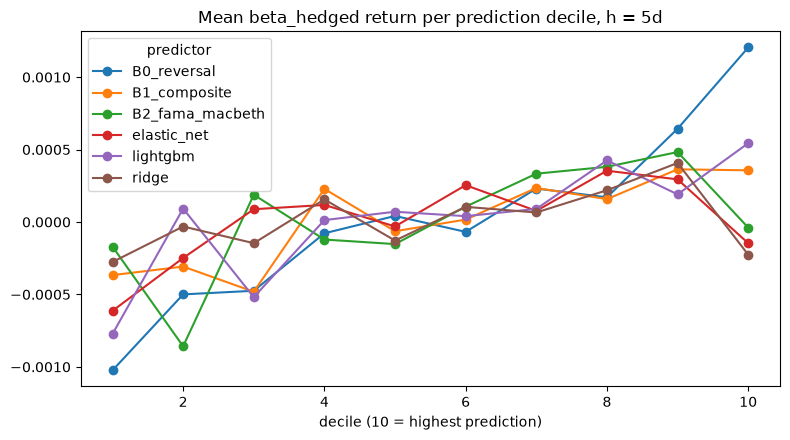

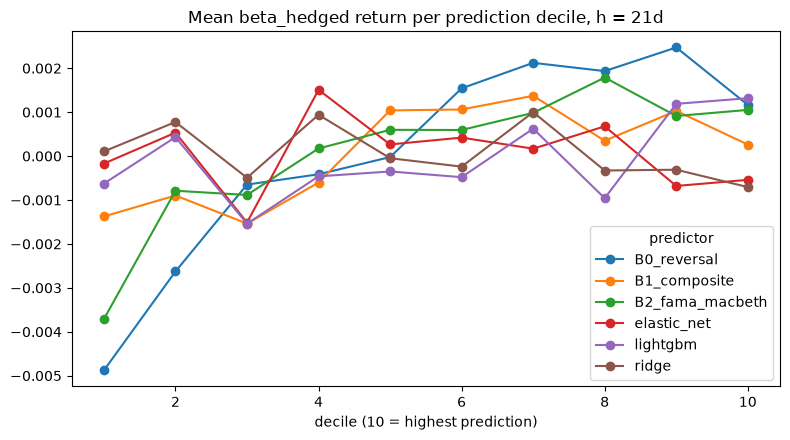

In [6]:
for h in (5, 21):
    plots.plot_decile_means(read("decile_means"), h, "rank", "beta_hedged");

- **The portfolio spreads agree with the ICs.** LightGBM on the 5-day rank target has the only clearly significant
  rank spread (2.0 percentile points per 5 days, t 3.15). Its beta-hedged spread is 13 bp per 5 days (t 1.42). B0
  earns more in beta-hedged terms (22 bp, t 1.92), but trades about 86% of each leg every rebalance.
- **The models trade less than B0.** On the rank target, prediction rank autocorrelation between rebalances is
  0.4-0.8 for the models, against about 0 for B0 (raw-target models: 0.14-0.29). LightGBM still turns over 54% / 75% of its legs every 5 days.
- **The models' top decile has lower beta.** On the rank target the top-minus-bottom beta gap is -0.13 to -0.46: the
  models load on low-vol and momentum. That is why hedging matters: raw spreads look worse than beta-hedged ones in
  the rising post-2009 market.
- No costs are applied here; the break-even analysis in the diagnostics says a 5-day reversal book needs costs
  below about 4 bp per side after 2010.

## 4. Stability

In [7]:
display(period_table(OUT, "rank").round(4))

label                       gfc  y2010_2019  post2020   first  second
horizon predictor                                                    
5       B0_reversal      0.0167      0.0118    0.0081  0.0165  0.0082
        B1_composite     0.0185      0.0178    0.0036  0.0167  0.0156
        B2_fama_macbeth  0.0021      0.0161   -0.0026  0.0116  0.0101
        elastic_net      0.0127      0.0149    0.0029  0.0156  0.0102
        lightgbm         0.0180      0.0193    0.0070  0.0202  0.0146
        ridge            0.0075      0.0143    0.0066  0.0136  0.0103
21      B0_reversal      0.0096      0.0131   -0.0031  0.0093  0.0113
        B1_composite     0.0043      0.0193   -0.0366  0.0098  0.0083
        B2_fama_macbeth -0.0210      0.0013   -0.0136 -0.0032 -0.0069
        elastic_net     -0.0173      0.0004   -0.0035 -0.0051 -0.0023
        lightgbm        -0.0061      0.0114   -0.0033  0.0076  0.0044
        ridge           -0.0354     -0.0029   -0.0095 -0.0145 -0.0061

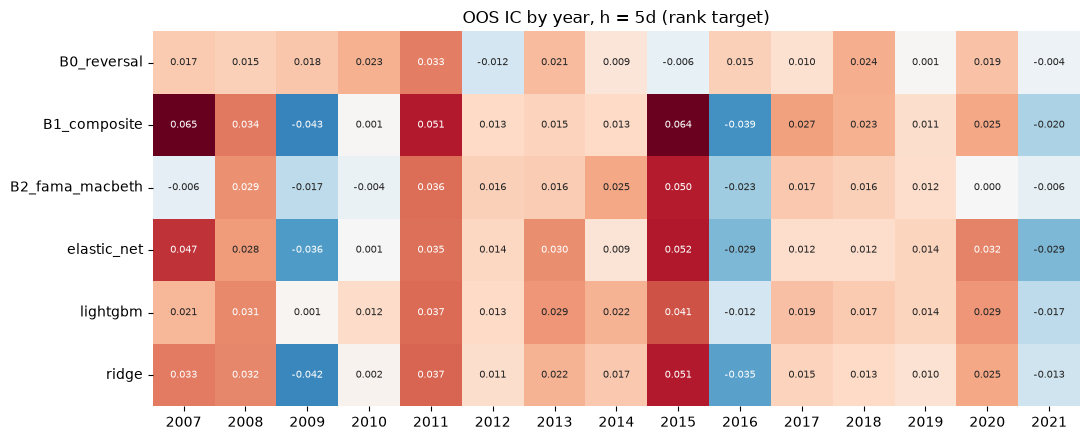

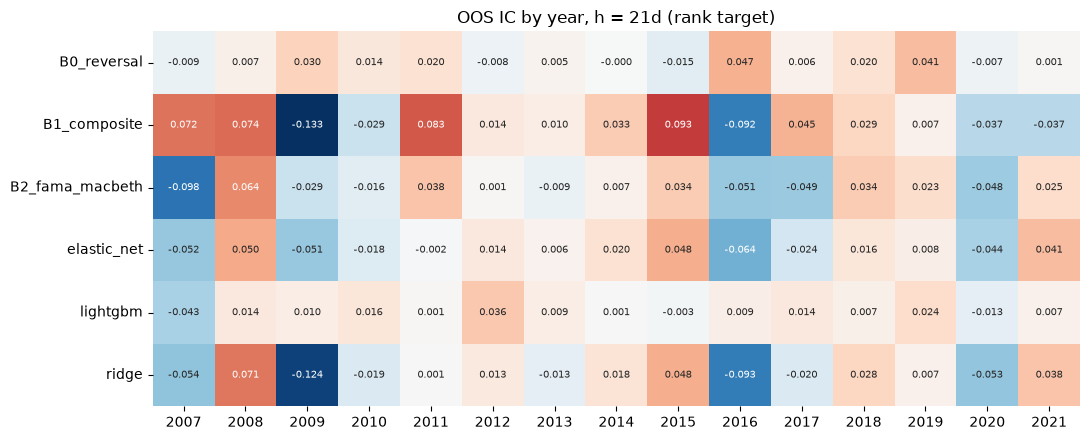

In [8]:
for h in (5, 21):
    plots.plot_ic_by_year(read("ic_stability"), h, "rank");

In [9]:
decay = read("ic_decay")
display(decay[decay["variant"].isin(["rank", "none"])].pivot_table(index="k", columns="column", values="ic_mean")
        .iloc[[0, 1, 2, 4, 9, 14, 20]].round(4))

column,B0_reversal_h21,B0_reversal_h5,B1_composite_h21,B1_composite_h5,B2_fama_macbeth_h21_rank,B2_fama_macbeth_h5_rank,elastic_net_h21_rank,elastic_net_h5_rank,lightgbm_h21_rank,lightgbm_h5_rank,ridge_h21_rank,ridge_h5_rank
k,,,,,,,,,,,,
0,0.0078,0.0078,0.0166,0.0166,0.0039,0.0104,0.0088,0.0130,0.0056,0.0133,0.0091,0.0125
1,0.0062,0.0062,0.0163,0.0163,0.0050,0.0110,0.0092,0.0129,0.0055,0.0134,0.0098,0.0136
2,0.0035,0.0035,0.0159,0.0159,0.0037,0.0106,0.0080,0.0118,0.0046,0.0116,0.0084,0.0124
4,0.0014,0.0014,0.0153,0.0153,0.0027,0.0087,0.0066,0.0100,0.0042,0.0099,0.0072,0.0114
9,0.0031,0.0031,0.0147,0.0147,0.0024,0.0077,0.0051,0.0085,0.0029,0.0086,0.0058,0.0088
14,-0.0018,-0.0018,0.0139,0.0139,-0.0000,0.0055,0.0042,0.0074,0.0015,0.0059,0.0055,0.0075
20,-0.0008,-0.0008,0.0141,0.0141,0.0001,0.0054,0.0037,0.0078,-0.0000,0.0066,0.0053,0.0084


- **LightGBM at 5 days is the most stable predictor:** IC 0.018 in 2007-09, 0.019 in 2010-19 (t 3.4) and 0.007 in
  2020-21 (t 0.4, under two years of data). Its first and second halves of the OOS window are 0.020 and 0.015.
- **B0 halves**, from 0.0165 to 0.0082, the same weakening reversal seen in the signal research.
- **At 21 days the linear models lose in the financial crisis** (Ridge -0.035, B2 -0.021 in 2007-09). Momentum
  crashed in 2009. These are the high-dispersion days on which, as the diagnostics showed, momentum ICs turn negative.
- **Decay:** B0's IC halves within about 2.6 days. On the rank target the models' ICs persist much longer (LightGBM
  5d: 16 days; Ridge: does not halve within 21 days), because part of their signal is slow momentum / low-vol.

## 5. What do the models use?

In [10]:
display(sign_table(OUT, "rank").round(4))

,elastic_net_h5,elastic_net_h21,ridge_h5,ridge_h21,lgbm_shap_dir_h5,lgbm_shap_dir_h21,prior_sign
feature,,,,,,,
z_beta_252d,-0.0010,-0.0012,-0.0012,-0.0004,-0.5451,-0.0915,0
z_dist_high_252d,-0.0023,-0.0021,-0.0018,-0.0016,0.2180,0.2146,1
z_intraday_ret,-0.0054,-0.0021,-0.0044,-0.0018,-0.8065,-0.6841,0
z_log_dollar_volume_21d,-0.0041,-0.0189,-0.0039,-0.0108,-0.6593,-0.7305,0
z_mom_12_1,0.0400,0.0143,0.0155,0.0053,0.8788,0.6247,1
z_overnight_ret,-0.0017,-0.0010,-0.0014,-0.0011,0.1062,-0.6578,0
z_ret_126d,0.0023,-0.0031,0.0029,-0.0013,0.6128,0.3100,1
z_ret_1d,-0.0004,-0.0006,-0.0006,-0.0003,-0.6781,-0.6815,-1
z_ret_21d,0.0100,0.0072,0.0042,0.0045,0.2562,-0.0405,0


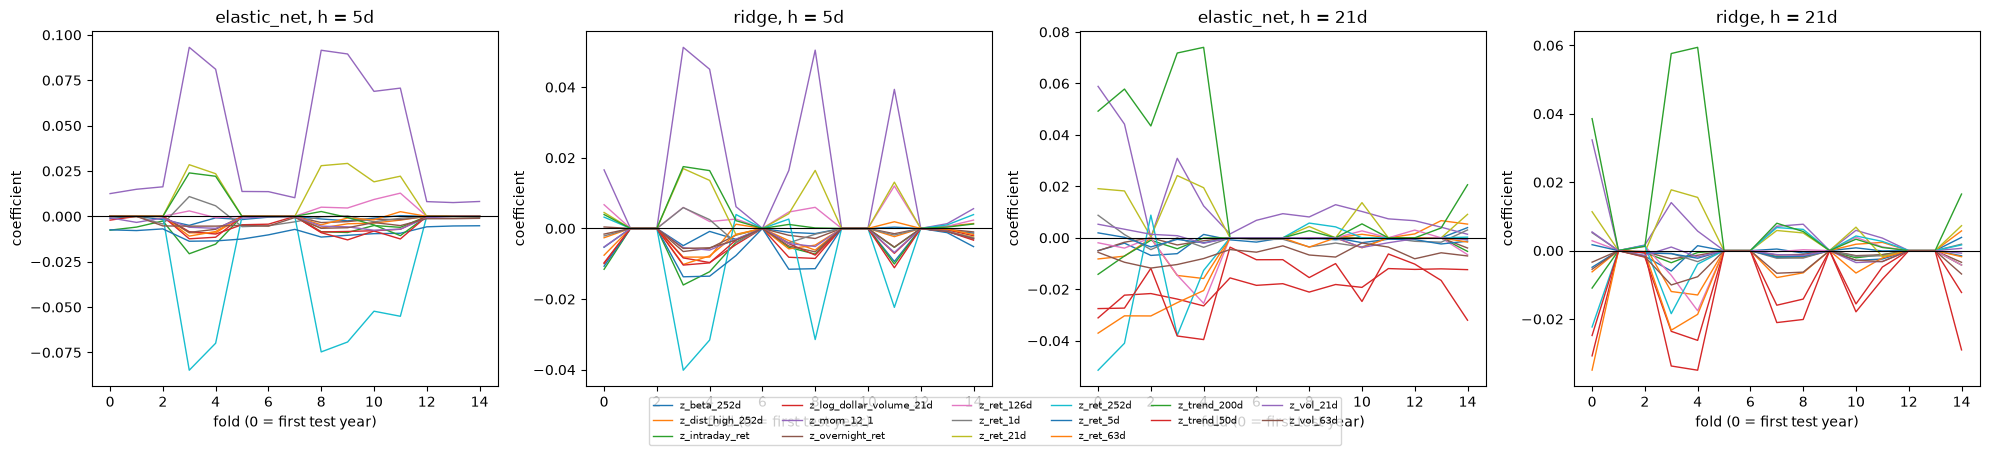

In [11]:
plots.plot_coefficient_paths(read("coefficients"), "rank");

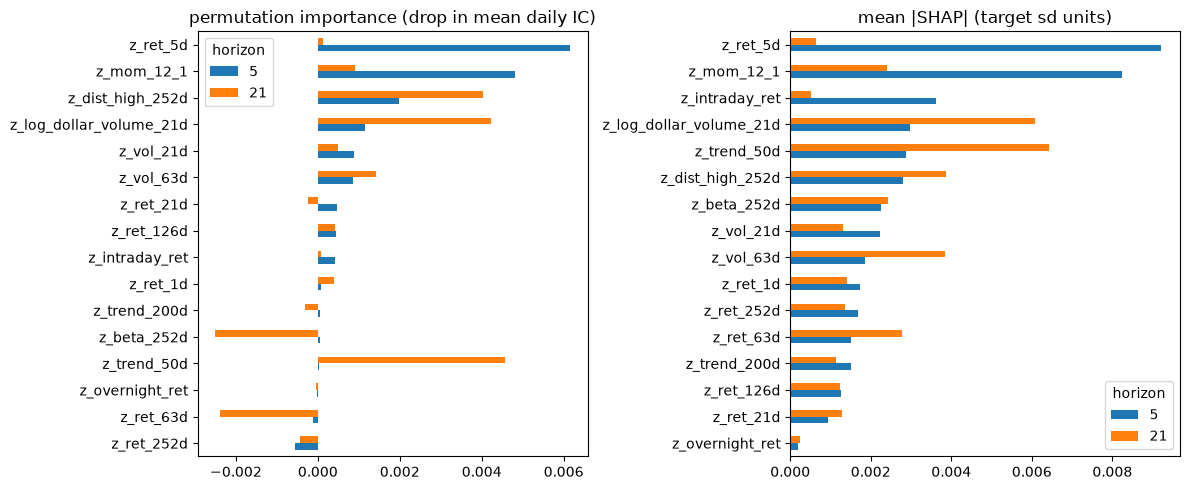

In [12]:
plots.plot_lightgbm_importance(read("lightgbm_permutation_importance"), read("lightgbm_shap"), "rank");

**Where the models agree with the signal research and its priors:**

- **LightGBM at 5 days** is driven by reversal and momentum. `z_ret_5d` and `z_mom_12_1` have the largest
  permutation importance (drops in IC of 0.0061 and 0.0048). The SHAP values have the expected signs (correlation with
  the feature -0.81 and +0.88), matching the multivariate Fama-MacBeth (reversal strong, momentum weak but positive).
- **Intraday return** enters with a negative sign in every model, the reversal effect again.
- **Volatility and beta** are negative almost everywhere (low-vol prior).

**Where they do not:**

- **At 21 days LightGBM shifts away from reversal.** Its importance moves to `z_log_dollar_volume_21d` (negative:
  small names), `z_trend_50d` (negative) and `z_dist_high_252d` (positive). `z_ret_5d` drops to about zero.
- **`z_dist_high_252d` and `z_trend_50d` have negative linear coefficients** against a +1 prior. `trend_50d` had a
  negative IC at 21 days in the signal research too (-0.018), so the data, not the model, disagrees with the prior.
  LightGBM gives `dist_high` its expected positive direction.
- **The linear coefficients are small and partly offset across correlated features.** `z_mom_12_1` is positive while
  `z_ret_252d` is negative (together roughly a short one-month return, i.e. monthly reversal). `z_trend_200d` is
  positive and `z_trend_50d` negative. `z_ret_63d` and `z_ret_252d` therefore come out against their +1 priors.
  This is collinearity, not evidence against momentum.
- **Ridge puts little weight on `z_ret_5d`** (-0.006 at 5 days, about 0 at 21 days) or `z_ret_1d` (about 0), even
  though they are the strongest univariate signals. The largest reversal coefficient is on `z_intraday_ret` (-0.004);
  `z_ret_21d` even comes out positive (+0.004), partly offset by the `z_mom_12_1` / `z_ret_252d` contrast.

**Hyperparameter selection is noisy.** Ridge alpha jumps between 0.01 and 1000 across folds (the validation IC is
almost flat in alpha), Elastic Net alpha between 1e-4 and 1e-2. LightGBM early-stops after a median of 9 to 33
trees at learning rate 0.05 (fewest on the raw target), so the boosted models are very small.


In [13]:
hp = read("hyperparameters")
display(hp.groupby(["model", "horizon", "variant"])[["alpha", "l1_ratio", "num_leaves", "min_data_in_leaf",
                                                    "lambda_l2", "n_rounds"]].median())

alpha  l1_ratio  num_leaves  min_data_in_leaf  lambda_l2  n_rounds
model       horizon variant                                                                    
elastic_net 5       rank     0.010       0.9         NaN               NaN        NaN       NaN
                    raw      0.010       0.9         NaN               NaN        NaN       NaN
            21      rank     0.003       0.5         NaN               NaN        NaN       NaN
                    raw      0.003       0.5         NaN               NaN        NaN       NaN
lightgbm    5       rank       NaN       NaN        15.0           10000.0        1.0      33.0
                    raw        NaN       NaN         7.0            2000.0       50.0      10.0
            21      rank       NaN       NaN        15.0            2000.0        1.0      15.0
                    raw        NaN       NaN        15.0            2000.0        1.0       9.0
ridge       5       rank     1.000       NaN         NaN               NaN        NaN       NaN
                    raw      1.000       NaN         NaN               NaN        NaN       NaN
            21      rank     1.000       NaN         NaN               NaN        NaN       NaN
                    raw      1.000       NaN         NaN               NaN        NaN       NaN

## 6. Which feature families carry the result?

Ridge (both targets) and LightGBM (primary target, hyperparameters fixed to each fold's choice in the full model):
each family on its own, and the model with that family left out.

In [14]:
display(ablation_table(OUT).round(4))

all_features  single_family  leave_one_family_out
model    horizon variant family                                                               
lightgbm 5       rank    liquidity_size            0.0174         0.0005                0.0173
                         momentum                  0.0174         0.0094                0.0166
                         overnight_intraday        0.0174         0.0050                0.0180
                         reversal                  0.0174         0.0142                0.0141
                         risk                      0.0174         0.0050                0.0181
                         trend                     0.0174         0.0111                0.0147
         21      rank    liquidity_size            0.0060         0.0027                0.0056
                         momentum                  0.0060        -0.0076                0.0116
                         overnight_intraday        0.0060         0.0069                0.0085
                         reversal                  0.0060         0.0146                0.0054
                         risk                      0.0060        -0.0057                0.0086
                         trend                     0.0060         0.0115               -0.0019
ridge    5       rank    liquidity_size            0.0120         0.0004                0.0126
                         momentum                  0.0120         0.0079                0.0112
                         overnight_intraday        0.0120         0.0063                0.0123
                         reversal                  0.0120         0.0112                0.0115
                         risk                      0.0120         0.0076                0.0119
                         trend                     0.0120         0.0065                0.0132
                 raw     liquidity_size            0.0059         0.0004                0.0050
                         momentum                  0.0059         0.0057                0.0052
                         overnight_intraday        0.0059         0.0066                0.0050
                         reversal                  0.0059         0.0111                0.0042
                         risk                      0.0059        -0.0080                0.0064
                         trend                     0.0059         0.0058                0.0063
         21      rank    liquidity_size           -0.0103         0.0031               -0.0062
                         momentum                 -0.0103        -0.0190               -0.0034
                         overnight_intraday       -0.0103         0.0049               -0.0109
                         reversal                 -0.0103         0.0098               -0.0134
                         risk                     -0.0103         0.0029               -0.0018
                         trend                    -0.0103        -0.0018               -0.0124
                 raw     liquidity_size           -0.0029         0.0031               -0.0053
                         momentum                 -0.0029        -0.0147               -0.0015
                         overnight_intraday       -0.0029         0.0052               -0.0020
                         reversal                 -0.0029         0.0087               -0.0021
                         risk                     -0.0029        -0.0071               -0.0027
                         trend                    -0.0029        -0.0017               -0.0088

- **At 5 days reversal on its own is about as good as all 16 features.** Ridge: 0.0112 (t 2.61) vs 0.0120
  (t 1.73). LightGBM: 0.0142 (t 3.56) vs 0.0174 (t 3.50). The extra families add little IC and a lot of variance.
- **Leaving reversal out barely hurts.** Ridge drops to 0.0115 and LightGBM to 0.0141, because
  `intraday_ret` (overnight/intraday family) and `ret_21d` carry overlapping reversal information.
- **For LightGBM, trend (0.0111, t 2.6) and overnight/intraday (0.0050, t 2.6) are the only other families with
  t above 2 on their own.** Risk and liquidity/size alone are about zero.
- **At 21 days momentum on its own is negative** (Ridge -0.019, LightGBM -0.008), and reversal on its own is the best
  predictor (Ridge 0.0098, t 1.4; LightGBM 0.0146, t 2.7). Mainly momentum drags the full models down: leaving it
  out lifts Ridge from -0.010 to -0.003 and LightGBM from 0.006 to 0.012.

## 7. Terminal-label sensitivity

In [15]:
display(read("terminal_sensitivity").round(4))

,horizon,best_model,variant,ic_mean_all,nw_t_all,ic_mean_ex_terminal,nw_t_ex_terminal,terminal_rows_oos
0,5,lightgbm,rank,0.0174,3.4956,0.0174,3.4964,847
1,21,lightgbm,rank,0.0060,0.9276,0.0059,0.9175,3663


Excluding delisting exits does not change the best model's IC (5 days: 0.0174 both ways; 21 days: 0.0060 vs 0.0059).

## Conclusion

- **Complexity does not improve the out-of-sample forecast by a significant margin.** No step (shrinkage, sparsity,
  non-linearity) beats the step before it, or beats the simple baselines, after Holm adjustment. The null result
  stands.
- **The point estimates do rank LightGBM first.** It is the only predictor with a Holm-significant OOS IC (5-day rank
  target, 0.017, t 3.5) and the most stable one across sub-periods. Its gain over a one-feature reversal score
  (+0.005 IC) is not statistically distinguishable from zero.
- **The forecastable signal is short-term reversal**, with momentum as a secondary input at 5 days. At 21 days no
  model has a significant IC, and the linear models are hurt by momentum's losses on high-dispersion days.
- **The rank target is the better choice for every model**, as the diagnostics predicted.

Whether any of this survives transaction costs is the next question; the costs and portfolio construction come later.